In [3]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df=pd.read_csv(r"C:\Users\VISHNU\Downloads\Internship\Dataset\Day-5\Data\Netflix_cleaned.csv")
#Display dataset
print("Dataset loaded sucessfully!")

print("shape:",df.shape)
display(df.head(10))

Dataset loaded sucessfully!
shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,",,,F,,,r,,,a,,,n,,,c,,,e,,,",9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,",,,B,,,r,,,a,,,z,,,i,,,l,,,",9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,Tv Show,The Great British Baking Show,Andy Devonshire,",,,U,,,n,,,i,,,t,,,e,,,d,,,K,,,i,,,n,,,g,,,d,,...",9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,",,,I,,,n,,,d,,,i,,,a,,,",05-01-2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,",,,G,,,e,,,r,,,m,,,a,,,n,,,y,,,",9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,",,,I,,,n,,,d,,,i,,,a,,,",05-01-2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [6]:
#checking missing values
print("Missing Values:")
print(df.isnull().sum())

#checking duplicate records
print("\nDuplicate Records:",df.duplicated().sum())

#Remove duplicate Records
df.drop_duplicates(inplace=True)



Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Records: 0


In [7]:
#Convert date_addes into datetime
df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)
#clean rating column
df['rating'] = df['rating'].fillna('Not Rated')

#clean genre column
df['listed_in'] = df['listed_in'].fillna('unknown')

#Clean Content type
df['type'] = df['type'].str.strip()

# Clean genre formatting
df['listed_in'] = df['listed_in'].str.strip()

print("\nData cleaning completed!")

display(df.head())


Data cleaning completed!


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,",,,F,,,r,,,a,,,n,,,c,,,e,,,",2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,",,,B,,,r,,,a,,,z,,,i,,,l,,,",2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,",,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [8]:
#Analyze Content rating categories

# Calculate rating counts

rating_counts = df['rating'].value_counts()

print("Content Rating Distribution:")
print(rating_counts)

# Rating percentage
rating_percentage = (
    df['rating'].value_counts(normalize=True) * 100
).round(2)

print("\nRating Percentage:")
print(rating_percentage)

Content Rating Distribution:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Rating Percentage:
rating
TV-MA       36.46
TV-14       24.54
TV-PG        9.80
R            9.09
PG-13        5.57
TV-Y7        3.79
TV-Y         3.48
PG           3.27
TV-G         2.50
NR           0.90
G            0.47
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
Name: proportion, dtype: float64


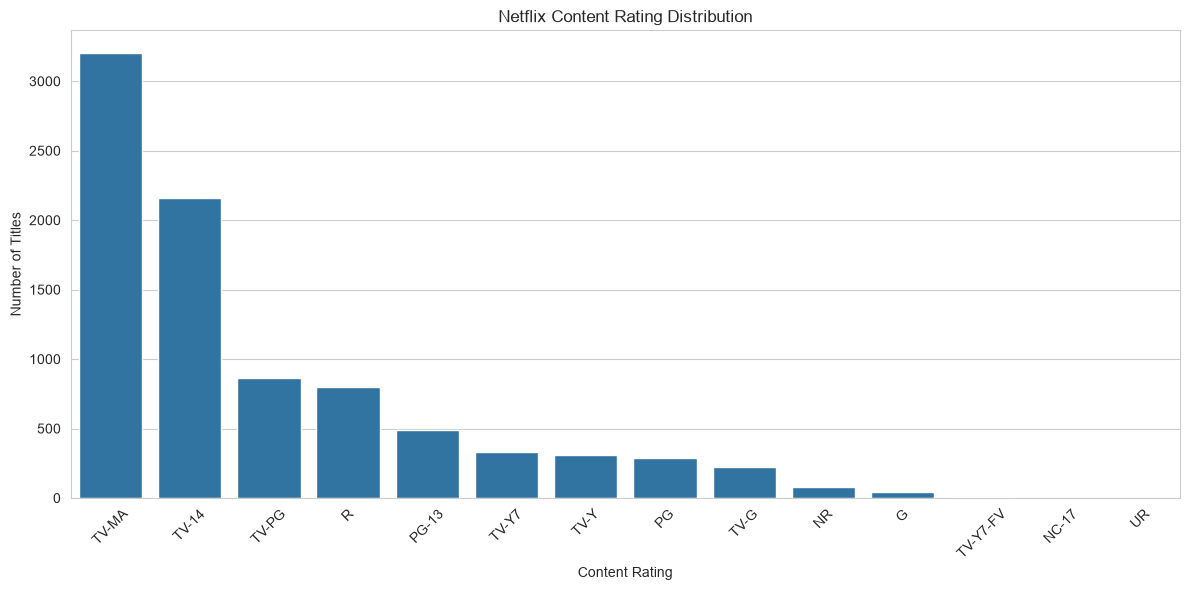

In [9]:
#Rating distribution – Bar chart
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='rating',
    order=df['rating'].value_counts().index
)

plt.title('Netflix Content Rating Distribution')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

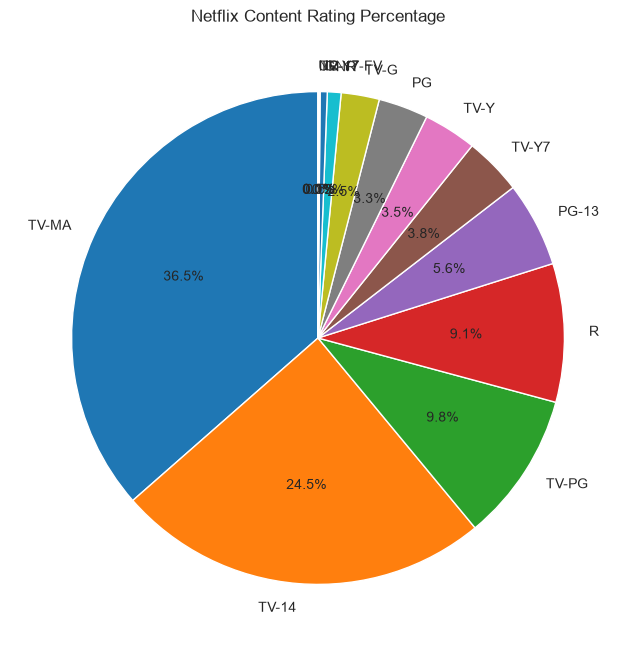

In [10]:
#Rating distribution – Pie chart
rating_counts = df['rating'].value_counts()

plt.figure(figsize=(10, 8))

plt.pie(
    rating_counts.values,
    labels=rating_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Netflix Content Rating Percentage')
plt.show()

In [11]:
#Interactive rating analysis
fig = px.bar(
    rating_counts.reset_index(),
    x='rating',
    y='count',
    title='Interactive Netflix Content Rating Analysis',
    labels={
        'rating': 'Content Rating',
        'count': 'Number of Titles'
    },
    color='rating',
    text_auto=True
)

fig.update_layout(
    xaxis_tickangle=-45,
    showlegend=False
)

fig.show()

In [12]:
#Identify the most common Netflix genres

# Split multiple genres into separate rows

genre_df = df.assign(
    genre=df['listed_in'].str.split(',')
).explode('genre')

# Remove extra spaces
genre_df['genre'] = genre_df['genre'].str.strip()

# Remove empty genres
genre_df = genre_df[
    genre_df['genre'].notna() &
    (genre_df['genre'] != '')
]

# Calculate genre frequency
genre_counts = genre_df['genre'].value_counts()

print("Top 20 Netflix Genres:")
print(genre_counts.head(20))

Top 20 Netflix Genres:
genre
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Thrillers                    577
TV Comedies                  573
Crime TV Shows               469
Kids' TV                     448
Docuseries                   394
Music & Musicals             375
Romantic TV Shows            370
Horror Movies                357
Stand-Up Comedy              343
Reality TV                   255
Name: count, dtype: int64


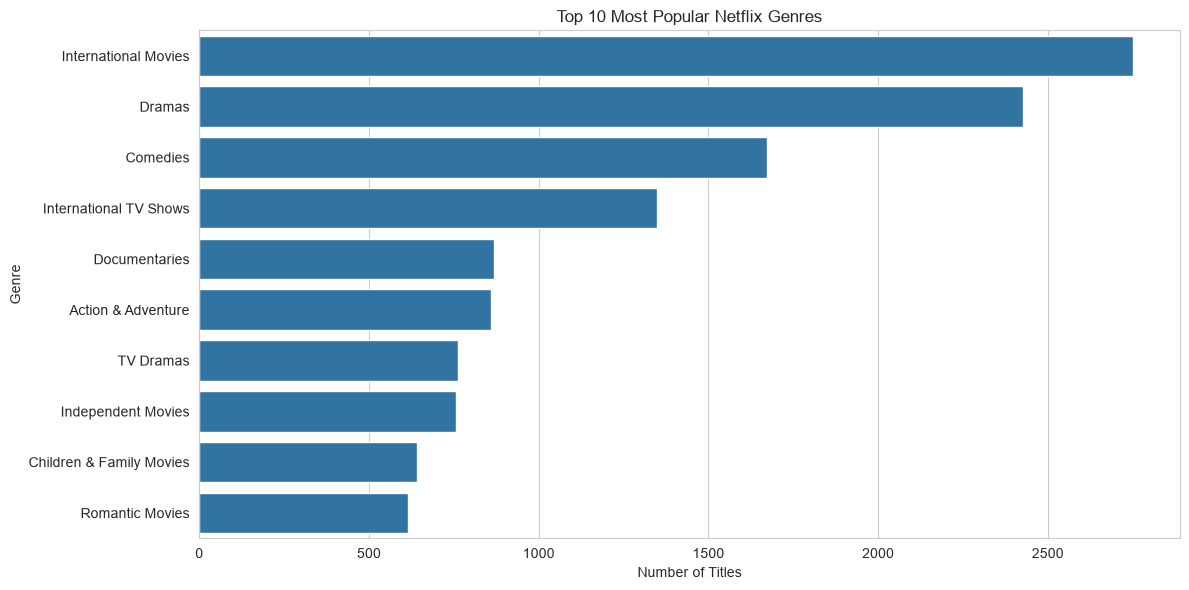

In [13]:
#Top 10 most common genres

top_genres = genre_counts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Most Popular Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

In [14]:
#Interactive genre analysis

genre_chart = px.bar(
    top_genres.reset_index(),
    x='count',
    y='genre',
    orientation='h',
    color='count',
    title='Top 10 Netflix Genres',
    labels={
        'count': 'Number of Titles',
        'genre': 'Genre'
    },
    text_auto=True
)

genre_chart.update_layout(
    yaxis={'categoryorder': 'total ascending'}
)

genre_chart.show()

Content Type Distribution:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


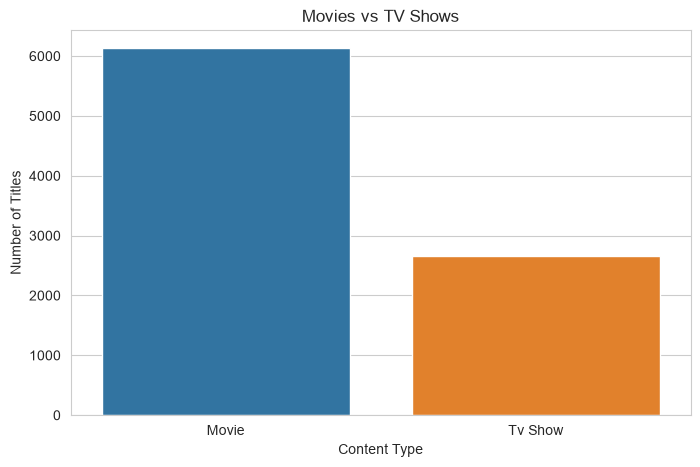

In [15]:
#Content type distribution

type_counts = df['type'].value_counts()

print("Content Type Distribution:")
print(type_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='type',
    hue='type',
    legend=False
)

plt.title('Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.show()

type      Movie  Tv Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


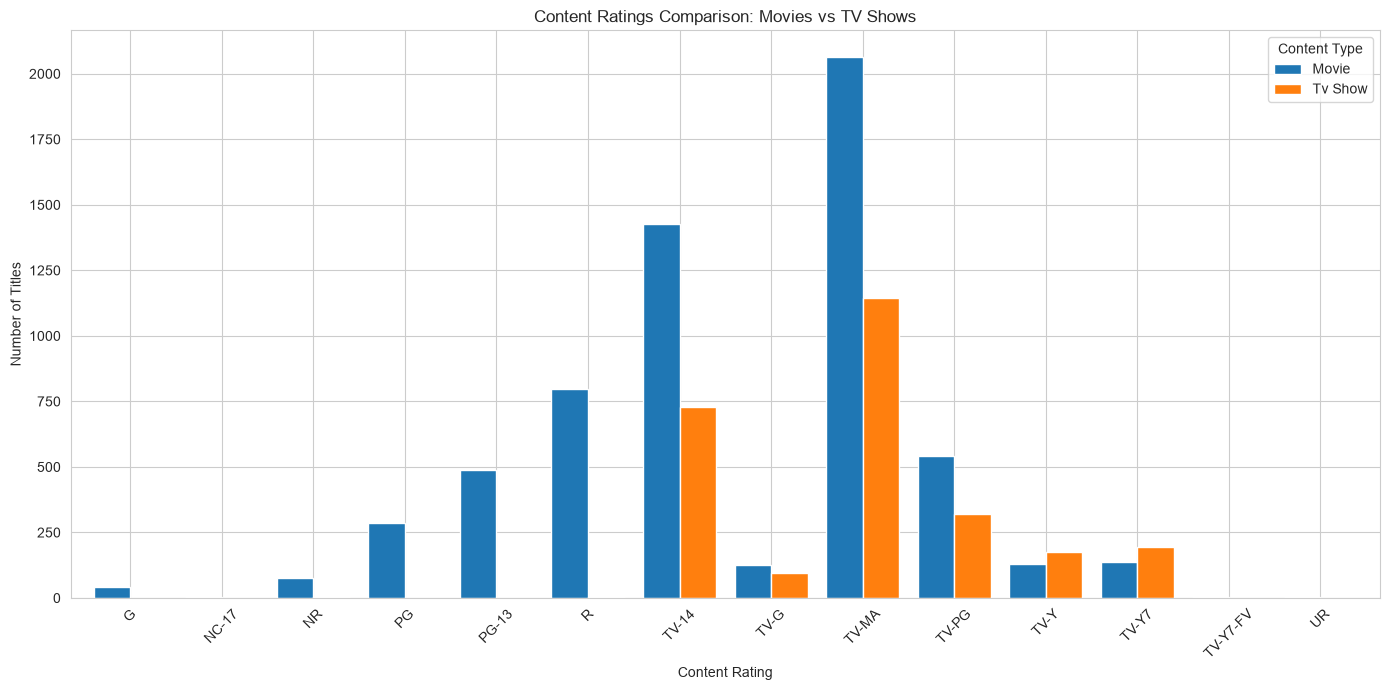

In [16]:
#Ratings comparison between Movies and TV Shows

rating_type = pd.crosstab(
    df['rating'],
    df['type']
)

print(rating_type)

rating_type.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Content Ratings Comparison: Movies vs TV Shows')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

type      Movie  Tv Show
rating                  
G          0.67     0.00
NC-17      0.05     0.00
NR         1.22     0.15
PG         4.68     0.00
PG-13      8.00     0.00
R         13.01     0.08
TV-14     23.29    27.40
TV-G       2.06     3.53
TV-MA     33.66    42.91
TV-PG      8.81    12.05
TV-Y       2.14     6.57
TV-Y7      2.27     7.28
TV-Y7-FV   0.08     0.04
UR         0.05     0.00


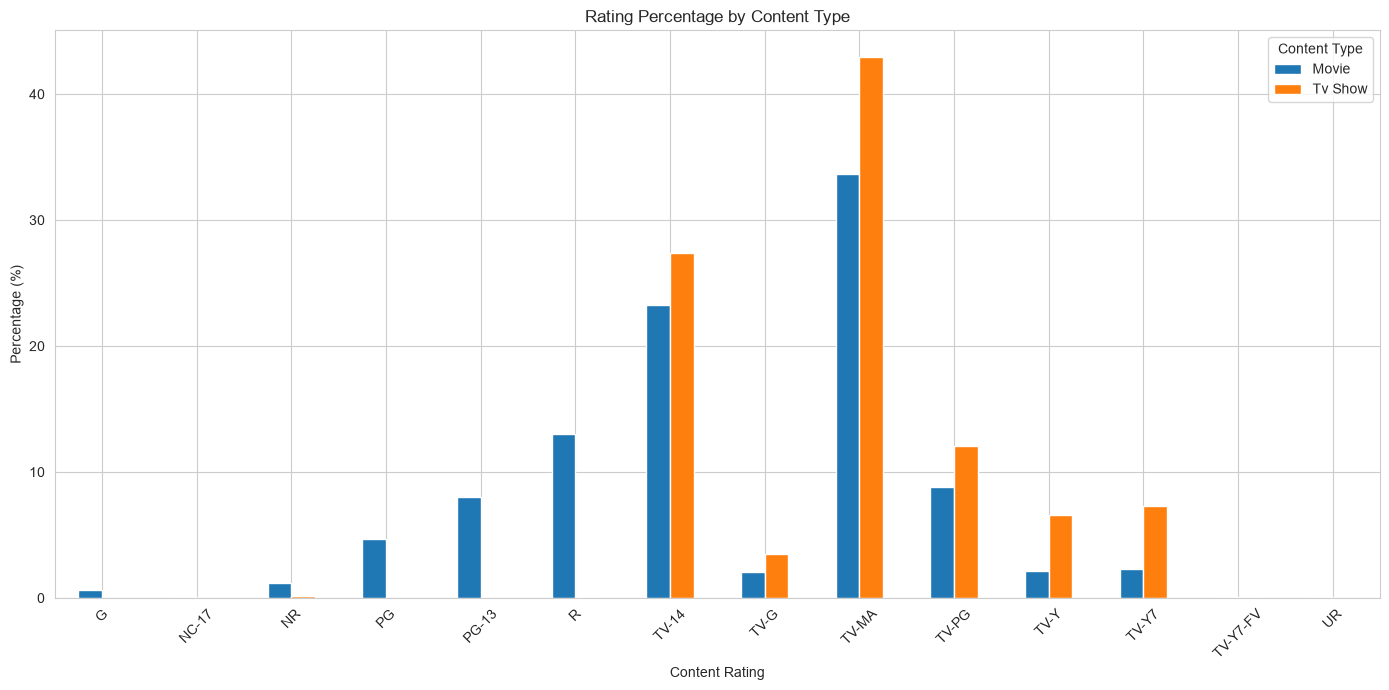

In [17]:
#Percentage comparison
rating_percentage_type = pd.crosstab(
    df['rating'],
    df['type'],
    normalize='columns'
) * 100

print(rating_percentage_type.round(2))

rating_percentage_type.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Rating Percentage by Content Type')
plt.xlabel('Content Rating')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

In [18]:
#Interactive rating comparison
fig = px.histogram(
    df,
    x='rating',
    color='type',
    barmode='group',
    title='Netflix Ratings by Movies and TV Shows',
    labels={
        'rating': 'Content Rating',
        'count': 'Number of Titles',
        'type': 'Content Type'
    }
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

In [19]:
#Audience segmentation analysis

# Define audience segmentation

audience_mapping = {
    'TV-Y': 'Kids',
    'TV-Y7': 'Kids',
    'TV-Y7-FV': 'Kids',
    'G': 'General Audience',
    'TV-G': 'General Audience',
    'PG': 'Family',
    'TV-PG': 'Family',
    'PG-13': 'Teenagers',
    'TV-14': 'Teenagers',
    'R': 'Adults',
    'TV-MA': 'Adults',
    'NC-17': 'Adults'
}

df['audience_segment'] = df['rating'].map(
    audience_mapping
).fillna('Not Classified')

# Audience segment counts

audience_counts = df['audience_segment'].value_counts()

print("Audience Segmentation:")
print(audience_counts)

Audience Segmentation:
audience_segment
Adults              4007
Teenagers           2647
Family              1148
Kids                 645
General Audience     261
Not Classified        82
Name: count, dtype: int64


In [20]:
#Audience segment visualization
fig = px.pie(
    names=audience_counts.index,
    values=audience_counts.values,
    title='Netflix Audience Segmentation',
    hole=0.4
)

fig.update_traces(
    textinfo='label+percent'
)

fig.show()

type              Movie  Tv Show
audience_segment                
Adults             2862     1145
Family              827      321
General Audience    167       94
Kids                275      370
Not Classified       78        4
Teenagers          1917      730


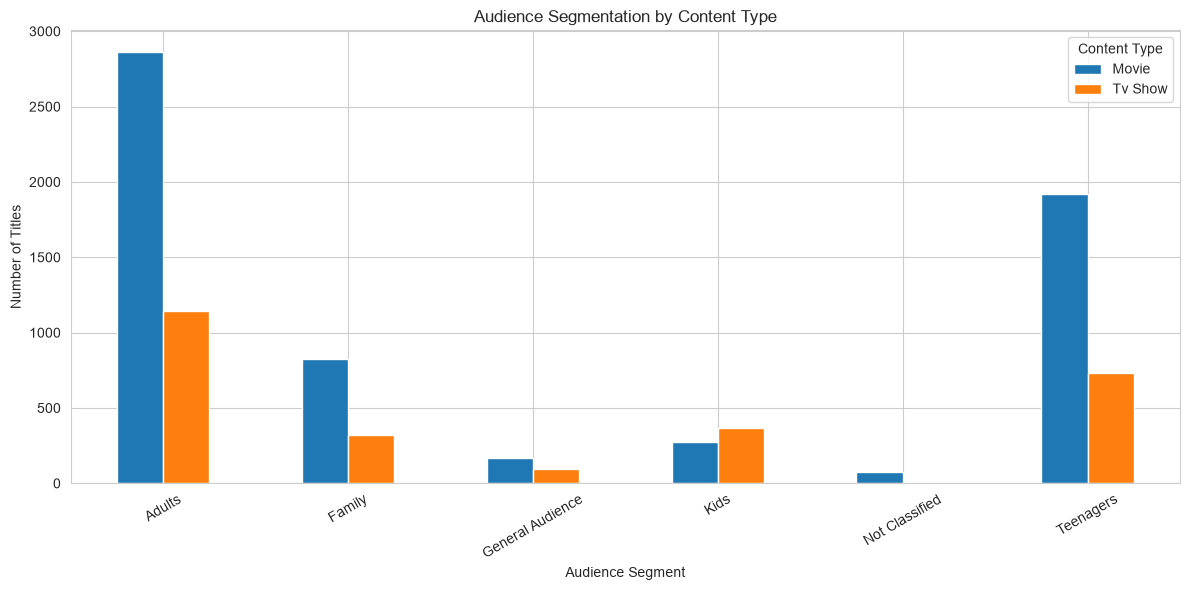

In [21]:
#Audience segmentation by content type
audience_type = pd.crosstab(
    df['audience_segment'],
    df['type']
)

print(audience_type)

audience_type.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Audience Segmentation by Content Type')
plt.xlabel('Audience Segment')
plt.ylabel('Number of Titles')
plt.xticks(rotation=30)
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

type                      Movie  Tv Show
genre                                   
International Movies       2752        0
Dramas                     2426        0
Comedies                   1674        0
International TV Shows        0     1349
Documentaries               869        0
Action & Adventure          859        0
TV Dramas                     0      762
Independent Movies          756        0
Children & Family Movies    641        0
Romantic Movies             616        0
Thrillers                   577        0
TV Comedies                   0      573
Crime TV Shows                0      469
Kids' TV                      0      448
Docuseries                    0      394


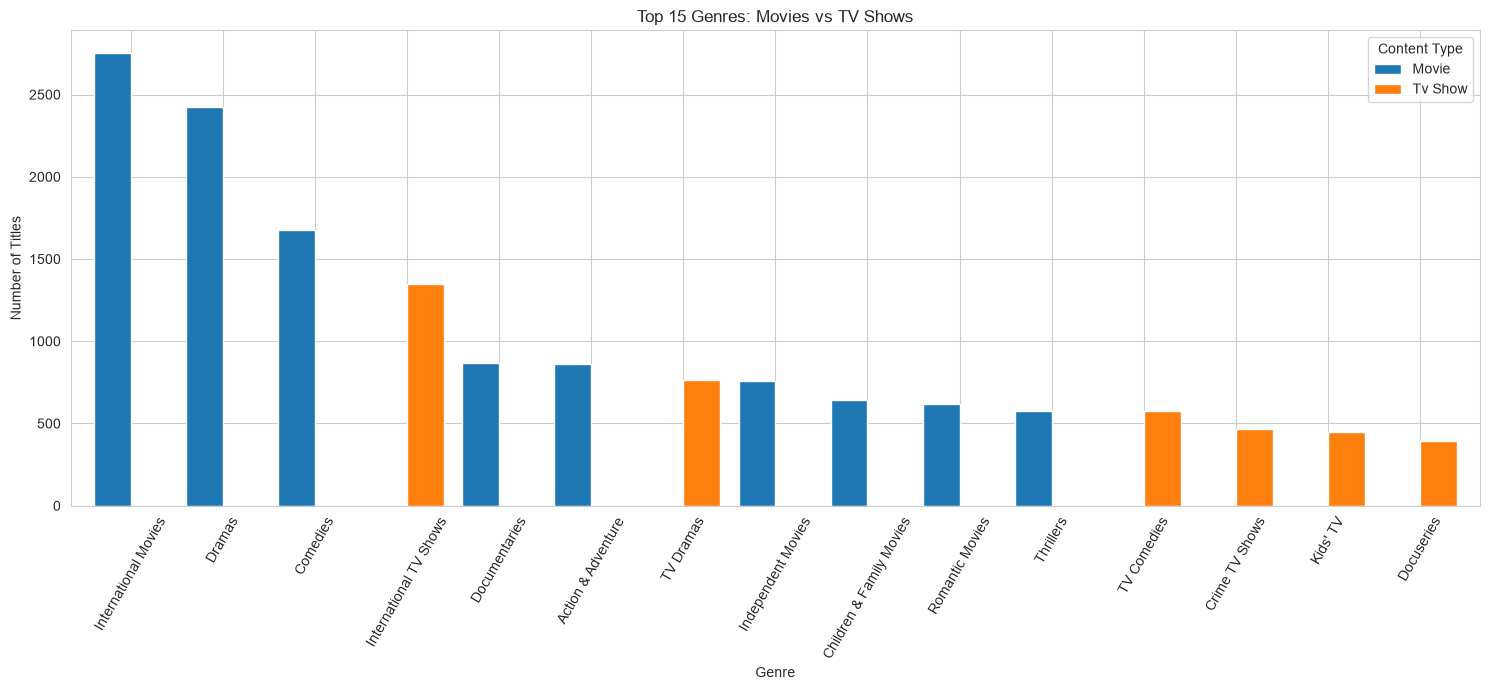

In [24]:
#Advanced genre analysis by content type

# Genre and content type analysis

genre_type = pd.crosstab(
    genre_df['genre'].reset_index(drop=True),
    genre_df['type'].reset_index(drop=True)
)

# Top 15 genres
top_15_genres = genre_type.sum(axis=1).nlargest(15).index

genre_type_top = genre_type.loc[top_15_genres]

print(genre_type_top)

# Visualization

genre_type_top.plot(
    kind='bar',
    figsize=(15, 7),
    width=0.8
)

plt.title('Top 15 Genres: Movies vs TV Shows')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.xticks(rotation=60)
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

In [25]:
#Interactive genre comparison
genre_type_reset = (
    genre_type_top
    .reset_index()
    .melt(
        id_vars='genre',
        var_name='Content Type',
        value_name='Number of Titles'
    )
)

fig = px.bar(
    genre_type_reset,
    x='genre',
    y='Number of Titles',
    color='Content Type',
    barmode='group',
    title='Interactive Genre Comparison'
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

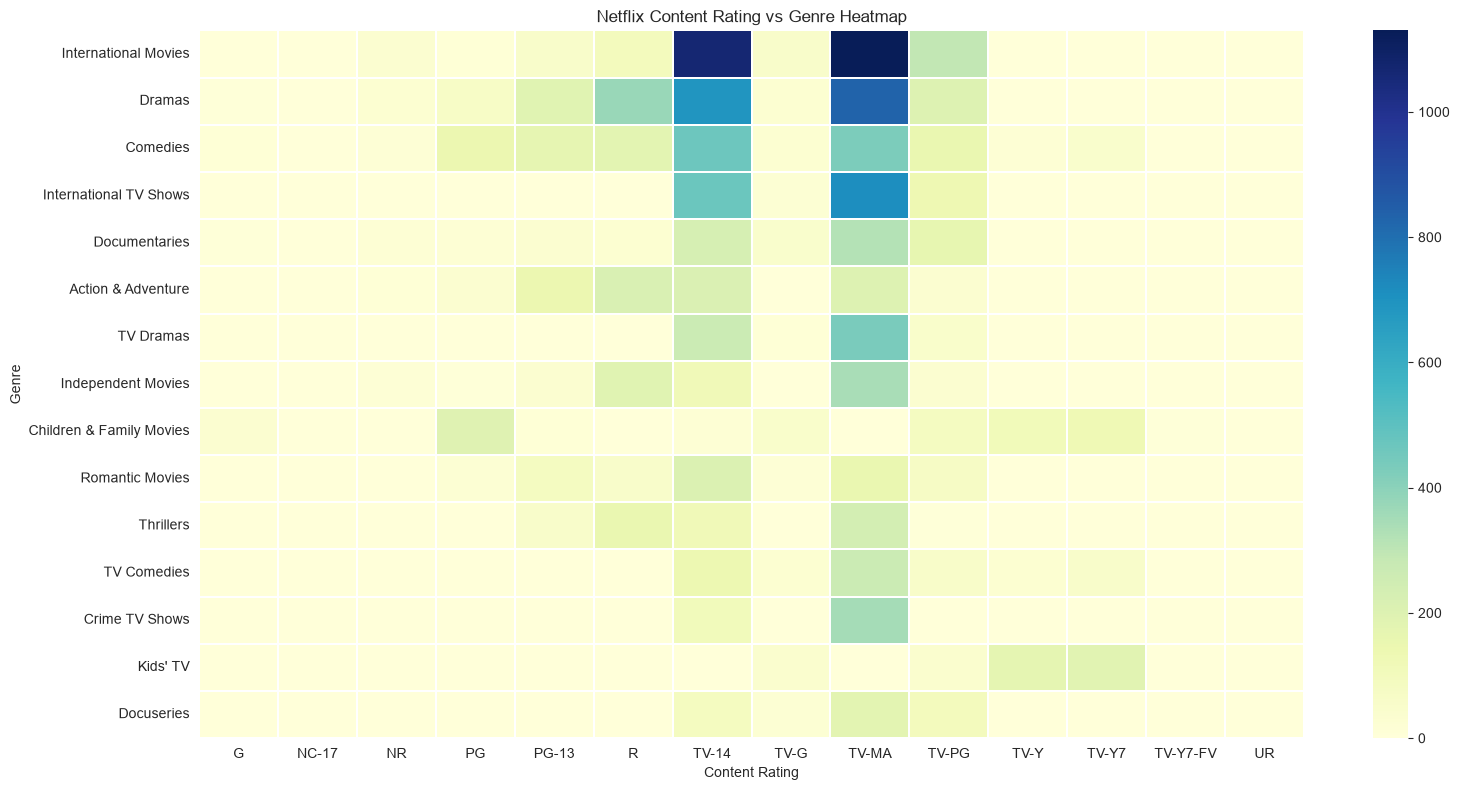

In [27]:
#Rating and genre relationship – Heatmap
# Create rating and genre cross-tabulation

rating_genre = pd.crosstab(
    genre_df['genre'].reset_index(drop=True),
    genre_df['rating'].reset_index(drop=True)
)

# Select top 15 genres
top_15 = genre_df['genre'].value_counts().head(15).index

rating_genre_top = rating_genre.loc[top_15]

# Heatmap

plt.figure(figsize=(16, 8))

sns.heatmap(
    rating_genre_top,
    annot=False,
    cmap='YlGnBu',
    linewidths=0.3
)

plt.title('Netflix Content Rating vs Genre Heatmap')
plt.xlabel('Content Rating')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

In [28]:
#Interactive dashboard using Plotly
from plotly.subplots import make_subplots

# Create dashboard

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        'Content Type Distribution',
        'Top 10 Genres',
        'Content Rating Distribution',
        'Audience Segmentation'
    ),
    specs=[
        [{'type': 'pie'}, {'type': 'bar'}],
        [{'type': 'bar'}, {'type': 'pie'}]
    ]
)

# Chart 1: Content type
fig.add_trace(
    go.Pie(
        labels=type_counts.index,
        values=type_counts.values,
        name='Content Type'
    ),
    row=1,
    col=1
)

# Chart 2: Top 10 genres
fig.add_trace(
    go.Bar(
        x=top_genres.values,
        y=top_genres.index,
        orientation='h',
        name='Genres'
    ),
    row=1,
    col=2
)

# Chart 3: Ratings
fig.add_trace(
    go.Bar(
        x=rating_counts.index,
        y=rating_counts.values,
        name='Ratings'
    ),
    row=2,
    col=1
)

# Chart 4: Audience segmentation
fig.add_trace(
    go.Pie(
        labels=audience_counts.index,
        values=audience_counts.values,
        name='Audience'
    ),
    row=2,
    col=2
)

fig.update_layout(
    title_text='Netflix Content Rating & Genre Analysis Dashboard',
    height=900,
    showlegend=True
)

fig.show()

In [29]:
#Generate automatic business insights
print("=" * 60)
print("NETFLIX CONTENT RATING & GENRE ANALYSIS")
print("=" * 60)

# Total content
print("\n1. TOTAL CONTENT")
print("Total Titles:", len(df))

# Movies vs TV Shows
print("\n2. CONTENT TYPE ANALYSIS")

for content, count in type_counts.items():
    percentage = (count / len(df)) * 100
    print(f"{content}: {count} ({percentage:.2f}%)")

# Most popular rating
print("\n3. MOST COMMON CONTENT RATING")

print(
    "Most Common Rating:",
    df['rating'].value_counts().idxmax()
)

# Most popular genre
print("\n4. MOST POPULAR GENRE")

print(
    "Top Genre:",
    genre_counts.idxmax()
)

print(
    "Genre Count:",
    genre_counts.max()
)

# Top 5 genres
print("\n5. TOP 5 GENRES")

print(genre_counts.head(5))

# Audience segment
print("\n6. LARGEST AUDIENCE SEGMENT")

print(audience_counts.idxmax())

# Most common rating by content type
print("\n7. MOST COMMON RATING BY CONTENT TYPE")

for content in df['type'].dropna().unique():
    subset = df[df['type'] == content]
    print(
        content,
        "->",
        subset['rating'].value_counts().idxmax()
    )

print("\n" + "=" * 60)
print("ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 60)

NETFLIX CONTENT RATING & GENRE ANALYSIS

1. TOTAL CONTENT
Total Titles: 8790

2. CONTENT TYPE ANALYSIS
Movie: 6126 (69.69%)
Tv Show: 2664 (30.31%)

3. MOST COMMON CONTENT RATING
Most Common Rating: TV-MA

4. MOST POPULAR GENRE
Top Genre: International Movies
Genre Count: 2752

5. TOP 5 GENRES
genre
International Movies      2752
Dramas                    2426
Comedies                  1674
International TV Shows    1349
Documentaries              869
Name: count, dtype: int64

6. LARGEST AUDIENCE SEGMENT
Adults

7. MOST COMMON RATING BY CONTENT TYPE
Movie -> TV-MA
Tv Show -> TV-MA

ANALYSIS COMPLETED SUCCESSFULLY!


In [30]:
#Export analysis results to Excel
# Create Excel report

with pd.ExcelWriter(
    'Netflix_Content_Rating_Genre_Analysis.xlsx',
    engine='openpyxl'
) as writer:

    df.to_excel(
        writer,
        sheet_name='Cleaned Data',
        index=False
    )

    rating_counts.to_frame(
        'Total Titles'
    ).to_excel(
        writer,
        sheet_name='Rating Analysis'
    )

    genre_counts.to_frame(
        'Total Titles'
    ).to_excel(
        writer,
        sheet_name='Genre Analysis'
    )

    rating_type.to_excel(
        writer,
        sheet_name='Rating by Content Type'
    )

    audience_counts.to_frame(
        'Total Titles'
    ).to_excel(
        writer,
        sheet_name='Audience Analysis'
    )

    genre_type.to_excel(
        writer,
        sheet_name='Genre by Content Type'
    )

print("Excel report exported successfully!")# Create Excel report

with pd.ExcelWriter(
    'Netflix_Content_Rating_Genre_Analysis.xlsx',
    engine='openpyxl'
) as writer:

    df.to_excel(
        writer,
        sheet_name='Cleaned Data',
        index=False
    )

    rating_counts.to_frame(
        'Total Titles'
    ).to_excel(
        writer,
        sheet_name='Rating Analysis'
    )

    genre_counts.to_frame(
        'Total Titles'
    ).to_excel(
        writer,
        sheet_name='Genre Analysis'
    )

    rating_type.to_excel(
        writer,
        sheet_name='Rating by Content Type'
    )

    audience_counts.to_frame(
        'Total Titles'
    ).to_excel(
        writer,
        sheet_name='Audience Analysis'
    )

    genre_type.to_excel(
        writer,
        sheet_name='Genre by Content Type'
    )

print("Excel report exported successfully!")

Excel report exported successfully!
Excel report exported successfully!
